# [WEEK 7] A/B Test Design — Assignment (학생용)

**과제 유형: B. 도구 활용형** (생성형 AI 사용 가능, 판단·검증·해석은 직접)

## 과제 목적

숙박 예약 앱의 분석팀이 **"promotion 채널 사용자의 목록 → 상세 전환율이 유독 낮다"**는 진단을 넘겨줬습니다.
이번 과제에서는 이 문제를 개선할 아이디어를 **검증 가능한 실험으로 설계**하고, **여러분이 쓴 설계서 그대로 실험을 돌려** 결과를 판정합니다.

과제의 무게중심은 코드가 아니라 **설계**입니다. 설계서에 적은 값(지표, 배정 단위, 표본, 기간, 중단 규칙)이 실제 실험 결과를 결정하고, 결과를 보기 전에 정한 **판정 규칙**대로 배포 여부를 결정해야 합니다.

> **진단 메모 → 처방 선택 → 가설 → 지표 → 배정 → 표본·기간 → 사전 판정 규칙 → 실행 → SRM 확인 → 검정 → 판정**

---

## 📝 기술블로그 활용 안내

이번 글은 **"진단 결과를 받아서, 개선안을 실험으로 검증한다"**는 흐름으로 작성해주세요. 다음 그로스 세션 글과 이어지는 시리즈가 됩니다.

- **Part 0**의 Q0 답변 → 글의 도입부 ("왜 가격 표시 오류 수정은 실험하지 않고, 화면 개선만 실험했는가")
- **Part 1.2 ~ 1.7**의 설계서 → 본문 "실험 설계" 섹션 (특히 1.5의 MDE–기간 그래프와 선택 근거)
- **Part 2.2 ~ 2.3**의 결과 표·그래프와 결정 메모 → 본문 "결과와 의사결정" 섹션
- (선택) **Part 3** 심화 결과 → "설계가 달랐다면?" 섹션

코드를 나열하지 말고, **왜 그렇게 설계했고 결과를 어떻게 판정했는지**를 중심으로 써주세요.

---

## 🤖 생성형 AI 활용 안내

AI 사용은 가능합니다. 다만 이 과제는 **본인이 고른 설계값**(아이디어, 지표, 대상, 기간, 중단 규칙)에 따라 실험 결과가 달라지기 때문에, AI의 일반론으로는 답이 맞지 않습니다.

- 코드 문법, 시각화, 오류 수정, 개념 확인에 활용 가능
- 수치와 판정은 반드시 **본인 데이터로 직접 계산한 결과**로
- 마지막 셀에 **AI 활용 방법과 대화 내역**을 꼭 붙여주세요

> 이번 과제에서 가장 많이 감점되는 실수: **결과를 보고 나서 판정 기준을 바꾸는 것**입니다.

---
# 0. 환경 설정

1. 라이브러리 셀 → **실험 시뮬레이터** 셀 → **분석 도우미** 셀을 차례로 실행하세요. (세 셀 모두 수정하지 마세요)
2. 그다음 데이터 생성 셀을 실행하세요. `SEED`는 고정값이라 모두 같은 사용자 데이터를 씁니다.
   **결과를 다르게 만드는 건 여러분의 설계**입니다.

데이터는 교육용 synthetic dataset입니다. 가상의 숙박 예약 앱 로그이며, 이후 그로스 세션 과제에서도 같은 앱이 등장합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
#@title ⚙️ 실험 시뮬레이터 — 수정하지 말고 실행하세요
# 이 셀은 "실험 전 로그"와 "여러분의 설계대로 돌아가는 A/B 실험 데이터"를 만들어 줍니다.
# 가상의 숙박 예약 앱 로그입니다. (이후 그로스 세션 과제에서도 같은 앱이 등장합니다)
import json, base64, math
import numpy as np
import pandas as pd

_CFG = json.loads(base64.b64decode(
    "eyJBIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA0MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMDEs"
    "ICJyb29tX3Byb21vIjogMC4wMSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0eSI6IDAuMCwgImFtb3VudCI6IDEu"
    "MCwgImNhbmNlbCI6IDAuMH0sICJCIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA3LCAiZGV0YWlsX290aGVyIjogMC4w"
    "NDUsICJyb29tIjogLTAuMDY1LCAicm9vbV9wcm9tbyI6IC0wLjA2NSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0"
    "eSI6IDAuMCwgImFtb3VudCI6IDEuMCwgImNhbmNlbCI6IDAuMH0sICJDIjogeyJkZXRhaWxfcHJvbW8iOiAwLjAx"
    "MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMCwgInJvb21fcHJvbW8iOiAwLjAsICJjb21wbGV0"
    "ZSI6IDAuMDMsICJub3ZlbHR5IjogMC4xLCAiYW1vdW50IjogMC45MiwgImNhbmNlbCI6IDAuMDR9fQ=="
).decode())

_CHANNELS = ["organic", "paid_search", "promotion", "referral"]
_CH_P = [0.38, 0.27, 0.20, 0.15]
_DEVICES = ["android", "ios", "web"]
_DV_P = [0.41, 0.38, 0.21]
_P_LIST = 0.925
_P_DETAIL = {"organic": 0.62, "paid_search": 0.60, "promotion": 0.49, "referral": 0.64}
_P_ROOM, _P_CHECKOUT = 0.66, 0.56
_PAY = {"ios": ([0.38, 0.12, 0.50]), "android": ([0.50, 0.15, 0.35]), "web": ([0.60, 0.18, 0.22])}
_METHODS = ["card", "bank_transfer", "simple_pay"]
_P_COMPLETE = {"card": 0.70, "bank_transfer": 0.66, "simple_pay": 0.69}
_POOL = 120_000                 # 앱 전체 활성 사용자
_DAILY_SESSIONS = 10_000        # 하루 검색 세션 (전체)
_EXP_START = pd.Timestamp("2026-03-02")
_CAMPAIGN_DAY = 8               # 실험 8일차부터 promotion 채널 대규모 광고 캠페인

METRICS = {
    # 지표 이름: (분자 컬럼, 분모 컬럼)  ※ 모두 "세션 단위 비율"
    "list_to_detail":       ("detail_view", "list_view"),
    "detail_to_room":       ("room_select", "detail_view"),
    "checkout_to_complete": ("payment_complete", "checkout"),
    "search_to_complete":   ("payment_complete", "search"),
    "cancel_rate":          ("cancelled", "payment_complete"),
    "revenue_per_search":   ("net_amount", "search"),
}


def _sig(x):
    return 1 / (1 + np.exp(-x))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _users(rng):
    n = _POOL
    u = pd.DataFrame({
        "user_id": np.arange(200001, 200001 + n),
        "channel": rng.choice(_CHANNELS, size=n, p=_CH_P),
        "device": rng.choice(_DEVICES, size=n, p=_DV_P),
        "user_type": rng.choice(["leisure", "business"], size=n, p=[0.72, 0.28]),
    })
    # 방문 빈도(사람마다 다름)와 구매 성향(사람마다 다름)
    u["visit_rate"] = rng.gamma(0.5, 1.0, size=n)
    u["visit_rate"] *= _DAILY_SESSIONS / u["visit_rate"].sum()
    u["propensity"] = rng.normal(0, 1.0, size=n)
    u["old_browser"] = (u["device"] == "web") & (rng.random(n) < 0.45)
    u.loc[u["old_browser"], "propensity"] -= 0.6
    return u


def _simulate_sessions(rng, users, days, start, group=None, idea=None, target="promotion",
                       campaign_from=None, unit="user"):
    """days일 동안의 세션을 만든다. group: user_id -> 'A'/'B' (None이면 처치 없음)"""
    lam0 = users["visit_rate"].to_numpy()
    is_promo_user = (users["channel"] == "promotion").to_numpy()
    rows = []
    cfg = _CFG.get(idea, None) if idea else None
    for d in range(days):
        camp = campaign_from is not None and (d + 1) >= campaign_from
        lam = np.where(is_promo_user & camp, lam0 * 1.4, lam0)
        cnt = rng.poisson(lam)
        idx = np.repeat(np.arange(len(users)), cnt)
        if len(idx) == 0:
            continue
        s = users.iloc[idx].reset_index(drop=True)
        n = len(s)
        s["day"] = d + 1
        s["session_start"] = (start + pd.to_timedelta(d, unit="D")
                              + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, size=n), unit="s"))
        # 처치 여부
        treat = np.zeros(n, dtype=bool)
        if group is not None:
            if unit == "session":
                in_exp = s["user_id"].isin(group.index).to_numpy()
                coin = rng.random(n) < 0.5
                s["group"] = np.where(in_exp, np.where(coin, "B", "A"), None)
            else:
                s["group"] = s["user_id"].map(group)
            treat = (s["group"] == "B").to_numpy()
        promo = (s["channel"] == "promotion").to_numpy()
        prop = s["propensity"].to_numpy()
        if camp:   # 캠페인으로 들어온 세션은 구매 의도가 상대적으로 약함
            prop = prop - np.where(promo, 0.35, 0.0)

        # 효과 크기 (세션 단위 배정이면 같은 사람이 두 화면을 오가며 효과가 일부 희석됨)
        dil = 0.8 if unit == "session" else 1.0
        e_detail = np.zeros(n); e_room = np.zeros(n); e_comp = np.zeros(n)
        if cfg is not None:
            nov = cfg["novelty"] * math.exp(-(d) / 4.0)
            e_detail = np.where(promo, cfg["detail_promo"] + nov, cfg["detail_other"] + nov * 0.5) * dil
            e_room = np.where(promo, cfg["room_promo"], cfg["room"]) * dil
            e_comp = np.full(n, cfg["complete"]) * dil
            e_detail *= treat; e_room *= treat; e_comp *= treat

        list_ = rng.random(n) < _P_LIST
        p_det = s["channel"].map(_P_DETAIL).to_numpy() + e_detail
        detail = list_ & (rng.random(n) < _sig(_logit(p_det) + prop))
        room = detail & (rng.random(n) < _sig(_logit(_P_ROOM + e_room) + 0.6 * prop))
        checkout = room & (rng.random(n) < _sig(_logit(np.full(n, _P_CHECKOUT)) + 0.4 * prop))
        dev = s["device"].to_numpy()
        pm = np.empty(n, dtype=object)
        for dv in _DEVICES:
            m = dev == dv
            pm[m] = rng.choice(_METHODS, size=m.sum(), p=_PAY[dv])
        pc = np.vectorize(_P_COMPLETE.get)(pm).astype(float) + np.where(dev == "web", 0.02, 0)
        bug = (dev == "ios") & (pm == "simple_pay")
        broken = bug & (s["session_start"] >= pd.Timestamp("2026-04-01")).to_numpy()
        pc = np.where(broken, 0.28, pc)
        complete = checkout & (rng.random(n) < np.clip(pc + e_comp, 0, 0.99))
        s["search"] = 1
        s["list_view"] = list_.astype(int)
        s["detail_view"] = detail.astype(int)
        s["room_select"] = room.astype(int)
        s["checkout"] = checkout.astype(int)
        s["payment_complete"] = complete.astype(int)
        s["payment_method"] = np.where(checkout, pm, None)
        acc = rng.choice(["hotel", "pension", "motel"], size=n, p=[0.5, 0.3, 0.2])
        mean_amt = pd.Series(acc).map({"hotel": 230_000, "pension": 175_000, "motel": 115_000}).to_numpy()
        amt = np.maximum(50_000, np.round(rng.normal(mean_amt, 40_000), -2))
        canc_p = np.full(n, 0.075)
        if cfg is not None:
            target_mask = promo if target == "promotion" else np.ones(n, dtype=bool)
            amt = np.where(treat & target_mask, np.round(amt * cfg["amount"], -2), amt)
            canc_p = np.where(treat, canc_p + cfg["cancel"], canc_p)
        s["amount"] = np.where(complete, amt, 0.0)
        s["cancelled"] = (complete & (rng.random(n) < canc_p)).astype(int)
        s["net_amount"] = np.where(s["cancelled"] == 1, 0.0, s["amount"])
        rows.append(s)
    out = pd.concat(rows, ignore_index=True)
    return out


def generate_pre_period(seed):
    """실험 직전 4주(2026-02-02 ~ 03-01)의 세션 로그. 기준선(baseline) 추정용"""
    rng = np.random.default_rng(seed)
    users = _users(rng)
    pre = _simulate_sessions(rng, users, 28, pd.Timestamp("2026-02-02"))
    pre = pre.drop(columns=["visit_rate", "propensity", "old_browser"])
    pre.insert(0, "session_id", [f"P{i:08d}" for i in range(len(pre))])
    return pre


def run_experiment(design, seed):
    """여러분의 설계(design)대로 실험을 돌려 세션 로그를 돌려줍니다."""
    need = ["idea", "target", "unit", "primary_metric", "guardrails", "alpha", "power",
            "mde_abs", "traffic_share", "duration_days", "stopping"]
    miss = [k for k in need if k not in design]
    if miss:
        raise ValueError(f"설계서에 빠진 항목이 있어요: {miss}")
    if design["idea"] not in ("A", "B", "C"):
        raise ValueError("idea는 'A', 'B', 'C' 중 하나예요")
    if design["primary_metric"] not in METRICS:
        raise ValueError(f"primary_metric은 {list(METRICS)} 중 하나예요")
    D = int(design["duration_days"])
    if not 3 <= D <= 42:
        raise ValueError("duration_days는 3~42일 사이로 정해주세요")

    rng = np.random.default_rng(seed)
    users = _users(rng)
    rng = np.random.default_rng(seed * 7919 + 17)
    eligible = users if design["target"] == "all" else users[users["channel"] == "promotion"]
    share = float(design["traffic_share"])
    eligible = eligible[rng.random(len(eligible)) < share]
    grp = pd.Series(np.where(rng.random(len(eligible)) < 0.5, "A", "B"), index=eligible["user_id"].to_numpy())

    sim_users = users[users["user_id"].isin(grp.index)]
    s = _simulate_sessions(rng, sim_users, D, _EXP_START, group=grp, idea=design["idea"],
                           target=design["target"], campaign_from=_CAMPAIGN_DAY, unit=design["unit"])

    # --- 데이터 수집 파이프라인 (실무에서 흔한 문제가 섞여 있을 수 있음) ---
    if design["idea"] == "B":
        lost = (s["group"] == "B") & s["old_browser"]
        lost_users = s.loc[lost, "user_id"].unique()
        drop_users = pd.Series(lost_users).sample(frac=0.95, random_state=seed).to_numpy()
        s = s[~s["user_id"].isin(drop_users)]

    # --- 중간 확인 후 중단 규칙 ---
    stopped = D
    if design["stopping"] == "peek":
        num, den = METRICS[design["primary_metric"]]
        for day in range(3, D + 1):
            sub = s[s["day"] <= day]
            a = sub[sub["group"] == "A"]; b = sub[sub["group"] == "B"]
            xa, na, xb, nb = a[num].sum(), a[den].sum(), b[num].sum(), b[den].sum()
            if min(na, nb) == 0:
                continue
            p = (xa + xb) / (na + nb)
            se = math.sqrt(p * (1 - p) * (1 / na + 1 / nb))
            z = (xb / nb - xa / na) / se if se > 0 else 0
            pval = 2 * (1 - 0.5 * (1 + math.erf(abs(z) / math.sqrt(2))))
            if pval < design["alpha"]:
                stopped = day
                break
        s = s[s["day"] <= stopped]

    s = s.drop(columns=["visit_rate", "propensity", "old_browser"]).reset_index(drop=True)
    s.insert(0, "session_id", [f"E{i:08d}" for i in range(len(s))])
    first = s.groupby("user_id")["session_start"].min()
    print(f"실험 기간: {_EXP_START.date()} ~ {(_EXP_START + pd.Timedelta(days=stopped - 1)).date()} "
          f"({stopped}일{' · 중간 확인 규칙으로 조기 종료' if stopped < D else ''})")
    print(f"실험에 노출된 사용자: {s['user_id'].nunique():,}명 / 세션: {len(s):,}개")
    print(f"참고: 실험 {_CAMPAIGN_DAY}일차({(_EXP_START + pd.Timedelta(days=_CAMPAIGN_DAY - 1)).date()})부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.")
    return s

In [3]:
#@title 🧰 분석 도우미 함수 — 수정하지 말고 실행하세요
from scipy import stats

def ratio_test(df, metric, alpha=0.05):
    """세션 단위 비율 지표를 A/B로 비교합니다.
    - naive : 세션 하나하나를 독립 관측으로 보고 계산한 표준오차
    - delta : 같은 사용자의 세션끼리 묶어서(사용자 단위) 계산한 표준오차 (Delta Method)
    """
    num, den = METRICS[metric]
    res = {}
    for g in ["A", "B"]:
        d = df[df["group"] == g]
        u = d.groupby("user_id")[[num, den]].sum()
        X, Y = u[num].to_numpy(float), u[den].to_numpy(float)
        n = len(u)
        R = X.sum() / Y.sum()
        var_delta = (X.var(ddof=1) - 2 * R * np.cov(X, Y, ddof=1)[0, 1] + R ** 2 * Y.var(ddof=1)) / (Y.mean() ** 2) / n
        sel = d[den].to_numpy(float) > 0
        per_session = d[num].to_numpy(float)[sel] / d[den].to_numpy(float)[sel]
        var_naive = per_session.var(ddof=1) / sel.sum()
        res[g] = dict(value=R, var_delta=var_delta, var_naive=var_naive, users=n, denom=Y.sum())
    diff = res["B"]["value"] - res["A"]["value"]
    se_d = np.sqrt(res["A"]["var_delta"] + res["B"]["var_delta"])
    se_n = np.sqrt(res["A"]["var_naive"] + res["B"]["var_naive"])
    z = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "metric": metric,
        "A": res["A"]["value"], "B": res["B"]["value"],
        "diff": diff, "rel_diff": diff / res["A"]["value"],
        "ci_low": diff - z * se_d, "ci_high": diff + z * se_d,
        "p_value": 2 * (1 - stats.norm.cdf(abs(diff / se_d))),
        "se_delta": se_d, "se_naive": se_n,
        "p_naive": 2 * (1 - stats.norm.cdf(abs(diff / se_n))),
    })


def aa_split(df, seed=0):
    """실험 전 데이터를 사용자 단위로 무작위 반반 나눠 가짜 A/B 그룹을 붙입니다 (A/A 테스트용)."""
    rng = np.random.default_rng(seed)
    users = df["user_id"].unique()
    g = pd.Series(np.where(rng.random(len(users)) < 0.5, "A", "B"), index=users)
    return df.assign(group=df["user_id"].map(g))

In [4]:
SEED = 73   # 모두 같은 값입니다. 수정하지 마세요.

pre = generate_pre_period(SEED)
print("실험 전 4주 세션 로그:", pre.shape)
display(pre.head())

실험 전 4주 세션 로그: (279534, 17)


,session_id,user_id,channel,device,user_type,day,session_start,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,P00000000,200011,organic,ios,leisure,1,2026-02-02 13:58:36,1,1,1,1,1,0,card,0.0000,0,0.0000
1,P00000001,200024,organic,web,business,1,2026-02-02 22:56:10,1,1,1,1,1,0,simple_pay,0.0000,0,0.0000
2,P00000002,200056,promotion,web,leisure,1,2026-02-02 08:24:30,1,1,0,0,0,0,None,0.0000,0,0.0000
3,P00000003,200064,paid_search,ios,business,1,2026-02-02 15:55:17,1,1,0,0,0,0,None,0.0000,0,0.0000
4,P00000004,200064,paid_search,ios,business,1,2026-02-02 19:10:07,1,1,0,0,0,0,None,0.0000,0,0.0000


## 데이터 구조 — `pre` (실험 전 4주, 1 row = 1 session)

| column | description |
|---|---|
| `session_id`, `user_id` | 세션 ID, 사용자 ID |
| `channel`, `device`, `user_type` | 사용자 속성 |
| `day`, `session_start` | 기간 내 일차(1~28), 세션 시작 시각 |
| `search` ~ `payment_complete` | 각 퍼널 단계 도달 여부 (0/1) |
| `payment_method` | 결제수단 (checkout 이전에는 결측) |
| `amount`, `cancelled`, `net_amount` | 결제금액, 취소 여부, 취소 제외 금액 |

실험 데이터(Part 2)는 여기에 `group` 컬럼(A = 대조군, B = 실험군)이 추가됩니다.

---
# Part 0. 상황 브리핑 — 무엇을 실험할 것인가?

2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

> **분석팀 메모**
> promotion(광고·프로모션) 채널로 들어온 사용자는 **목록 → 상세 전환율**이 다른 채널보다 10%p가량 낮다.
> 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

> **QA팀 이슈**
> 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다.
> 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

- **처방 ①** 상세 페이지 가격 표시 오류 수정 (총액 표시)
- **처방 ②** promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선

먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.

In [5]:
# [0-A] 채널별 목록 → 상세 전환율 (세션 단위)
# 힌트: 분자 = 상세 진입 세션 수, 분모 = 목록 진입 세션 수

channel_l2d = (
    pre.groupby("channel")
       .agg(list_sessions=("list_view", "sum"), detail_sessions=("detail_view", "sum"))
)
channel_l2d["list_to_detail"] = channel_l2d["detail_sessions"] / channel_l2d["list_sessions"]
display(channel_l2d.sort_values("list_to_detail"))

# [0-B] 채널별 퍼널 단계 전환율 — 목록→상세 말고 다른 단계에도 차이가 있는지 확인
steps = ["search", "list_view", "detail_view", "room_select", "checkout", "payment_complete"]
f = pre.groupby("channel")[steps].sum()
step_rates = pd.DataFrame({f"{a} → {b}": f[b] / f[a] for a, b in zip(steps[:-1], steps[1:])})
display(step_rates.round(3))

,list_sessions,detail_sessions,list_to_detail
channel,,,
promotion,52906,25408,0.4802
paid_search,69715,40094,0.5751
organic,97392,57318,0.5885
referral,38385,23229,0.6052


,search → list_view,list_view → detail_view,detail_view → room_select,room_select → checkout,checkout → payment_complete
channel,,,,,
organic,0.9240,0.5890,0.6910,0.6030,0.6980
paid_search,0.9260,0.5750,0.6870,0.5990,0.6900
promotion,0.9250,0.4800,0.7000,0.6120,0.6910
referral,0.9220,0.6050,0.6880,0.5950,0.6930


### Q0. 무엇을 A/B 테스트할 것인가?

1. 처방 ①과 ② 중 **A/B 테스트가 필요한 것**은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
2. 처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
3. "A/B 테스트를 하지 않는다"고 해서 **아무것도 측정하지 않는 것**은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요?

**답변:**

1. 처방 ②가 테스트가 필요할 것이다. promotion의 목록→상세 전환율은 48.02%로 다른 채널들에 비해 낮다. 반면 검색→목록은 약 92%로 목록→상세만큼 큰 격차는 없다. 따라서 목록 화면의 개선이 실제 행동을 바꾸는지 무작위 실험으로 검증을 해볼 필요가 있다.
2. 처방 ①은 확인된 가격 표시 오류이므로 수정하고 검증한다. 과제에서 잘못된 표시로 확인된 상태를 대조군에 계속 남기면 일부 사용자에게 불완전한 가격 정보를 제공하고, 결제 단계의 예상 밖 추가금액으로 신뢰를 해칠 수 있다. 또한 법·윤리상 시정해야 할 문제인지 여부를 전환율의 유의성으로 결정해서도 안 된다.
3. 숙소·기기·앱 버전·할인 조건별로 목록/상세/결제의 최종 가격 일치율, 세금·봉사료 누락 건수, 가격 관련 문의·민원, 오류율·로딩 시간·결제 실패율을 모니터링한다. 퍼널 전환율, 검색당 순매출, 취소·환불도 함께 확인하되, 단순 배포 전후 차이는 계절성·캠페인 영향이 섞일 수 있으므로 수정의 순수한 인과효과라고 단정하지 않는다. 가격 검증은 자동화된 회귀 검사와 표본 수동 확인을 병행한다.

---
# Part 1. 실험 설계서 (과제의 핵심)

이 Part에서 작성한 내용은 **결과를 보기 전의 약속**입니다. Part 2에서 결과를 본 뒤에는 Part 1을 수정하지 마세요.
(수정 이력은 Colab 버전 기록으로 확인할 수 있습니다)

## 1.1 개선 아이디어 선택

디자인팀이 promotion 유입 사용자를 위한 개선안 3개를 가져왔습니다. **하나를 골라** 실험하세요.

| 아이디어 | 내용 | 디자인팀의 근거 |
|---|---|---|
| **A** | 목록 화면 카드에 **프로모션 적용가(할인가)**를 표시 | 광고에서 본 할인가가 목록에 안 보여서 "광고랑 다르네" 하고 이탈한다 |
| **B** | 프로모션 대상 숙소를 **목록 최상단에 고정** | 프로모션으로 들어왔는데 해당 숙소를 찾기 어렵다 |
| **C** | 첫 방문 시 **할인 쿠폰 팝업** 노출 | 할인 혜택을 즉시 체감하게 하면 탐색이 늘어난다 |

- **선택한 아이디어:** A — 목록 카드에 프로모션 적용가 표시. 세금·봉사료를 포함한 최종 금액 기준으로 표시한다.
- **선택 이유 (분석팀 메모와 0-B 결과에 연결해서 2~3문장):** promotion의 목록→상세는 48.02%로 다른 채널의 57.51~60.52%보다 낮지만, 이후 단계에는 이만큼 큰 격차가 없다. 광고에서 본 혜택이 목록에서도 확인되면 가격의 불일치에 대한 의심과 탐색 부담이 줄어 상세 진입이 늘어날 수 있다. 따라서 진단된 구간에 직접 작용하고 추가 할인비 지출을 전제로 하지 않는 A를 먼저 검증한다.
- **이 아이디어가 실패한다면 어떤 이유 때문일까? (예상되는 부작용 1개 이상):** 낮은 전환이 화면보다 promotion 유입의 낮은 구매 의도 때문이라면 효과가 작을 수 있다. 또한 쿠폰 적용 조건이 불명확하면 가격에 끌린 클릭만 늘고 예약은 늘지 않거나, 조건을 뒤늦게 안 사용자가 취소를 할 수도 있다. 

## 1.2 가설 (Action → Behavior → Impact)

- **Action (무엇을 바꾸면):** promotion 사용자의 목록 카드에 기존 프로모션의 적용 조건과 세금·봉사료를 포함한 적용가를 표시한다. A그룹은 기존 화면, B그룹은 변경 화면을 제공하며 할인 자체는 새로 추가하지 않는다.
- **Behavior (사용자가 어떻게 행동해서):** 사용자가 광고에서 본 혜택을 목록에서 확인해 가격 불일치에 대한 의심과 탐색 비용이 줄고, 상세 화면으로 더 많이 진입한다.
- **Impact (어떤 지표가 어느 방향으로, 대략 얼마나):** promotion의 세션 단위 목록→상세 전환율이 기준선 48.02%에서 약 51.02%로, 절대 3%p(상대 약 6.25%) 개선될 것으로 가정한다. 검색→결제완료·검색당 순매출의 감소, 취소율 증가가 없는지도 확인한다. 통계 가설은 H0: R_B−R_A=0, H1: R_B−R_A≠0인 양측검정이며, 개선 판정에는 차이가 양수여야 한다.

> "사용성이 좋아질 것이다"처럼 측정할 수 없는 문장은 가설이 아닙니다.

## 1.3 지표 체계

이번 실험에 맞게 지표 체계를 설계하세요.
시뮬레이터가 계산할 수 있는 지표는 아래와 같습니다. (모두 **세션 단위 비율**)

| 지표 키 | 분자 | 분모 |
|---|---|---|
| `list_to_detail` | 상세 진입 세션 | 목록 진입 세션 |
| `detail_to_room` | 객실 선택 세션 | 상세 진입 세션 |
| `checkout_to_complete` | 결제완료 세션 | checkout 세션 |
| `search_to_complete` | 결제완료 세션 | 검색 세션 |
| `cancel_rate` | 취소된 예약 세션 | 결제완료 세션 |
| `revenue_per_search` | 취소 제외 결제금액 합 | 검색 세션 |

| 역할 | 지표 | 분자 / 분모 / Grain / Window | 왜 이 역할인가 |
|---|---|---|---|
| Primary (1개) | `list_to_detail` ↑ | 상세 진입 세션 합 / 목록 진입 세션 합 / 세션 단위 합계비율 / 2026-03-02~03-15 시작 세션의 해당 세션 내 행동 | 목록에서 혜택을 확인한 사용자가 상세로 이동한다는 가설에 가장 직접적이고 민감하다. |
| Guardrail | `search_to_complete` ↑ | 결제완료 세션 합 / 검색 세션 합 / 세션 단위 합계비율 / 동일한 14일 시작 세션의 해당 세션 내 행동 | 클릭만 늘고 최종 예약은 줄어드는 부작용을 감시한다. |
| Guardrail | `revenue_per_search` ↑ | 취소 제외 결제금액 합 / 검색 세션 합 / 세션당 원 / 동일한 14일 시작 세션에 기록된 금액·취소 | 예약의 수뿐 아니라 금전 가치가 악화되는지 확인한다. |
| Guardrail | `cancel_rate` ↓ | 취소된 예약 세션 합 / 결제완료 세션 합 / 세션 단위 합계비율 / 동일한 14일 시작 세션에 기록된 취소 | 조건 오해로 예약했다가 취소하는 문제가 늘어나는지 확인한다. |
| Secondary | `detail_to_room` ↑ | 객실 선택 세션 합 / 상세 진입 세션 합 / 세션 단위 합계비율 / 동일한 14일·해당 세션 내 | 상세 진입 증가가 후속 탐색으로 이어지는지 탐색한다. |
| Secondary | `checkout_to_complete` ↑ | 결제완료 세션 합 / checkout 세션 합 / 세션 단위 합계비율 / 동일한 14일·해당 세션 내 | 가격 기대 불일치가 결제 단계에 남는지 탐색한다. |

In [6]:
# [1.3-A] 실험 전 데이터로 각 지표의 기준값(baseline) 계산 — 대상: promotion 사용자
# 주석 빈칸: 아래 반복문은 각 지표의 (분자 합 / 분모 합)을 계산해 ________ 를 구한다.

target_pre = pre[pre["channel"] == "promotion"]

baseline = {}
for m, (num, den) in METRICS.items():
    baseline[m] = target_pre[num].sum() / target_pre[den].sum()

display(pd.Series(baseline, name="promotion baseline"))

list_to_detail              0.4802
detail_to_room              0.7003
checkout_to_complete        0.6911
search_to_complete          0.1317
cancel_rate                 0.0733
revenue_per_search     23,275.2790
Name: promotion baseline, dtype: float64

## 1.4 배정 단위와 대상

### 1.4-A. 배정 단위
분석팀의 진단은 **세션 단위** 전환율이었습니다. 그렇다면 실험의 **배정**도 세션 단위로 해야 할까요?

- `unit = "user"`: 한 사용자는 실험 기간 내내 같은 화면
- `unit = "session"`: 앱을 열 때마다 새로 배정

**선택과 이유 (2~3문장):** `unit="user"`로 정하고 실험 기간 내내 같은 사용자는 같은 화면을 본다. 지표가 세션 비율이라고 배정까지 세션 단위일 필요는 없으며, 가격 표시는 다음 방문의 기대에도 영향을 줄 수 있어 화면이 번갈아 나오는 경험과 이월 효과를 피해야 한다.

### 1.4-B. 대상 범위
- `target = "promotion"`: promotion 유입 사용자만 실험
- `target = "all"`: 모든 사용자 실험

**선택과 이유:** `target="promotion"`. 진단된 문제와 개선 가설이 이 채널을 대상으로 하므로 효과가 약한 다른 채널까지 합쳐 평균 효과가 희석되는 것을 피한다. 

### 1.4-C. 트래픽 투입 비율 (`traffic_share`, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?

**선택과 이유:** `traffic_share=1.0`으로 promotion 대상 전원을 실험에 포함하고, 그 안에서 A:B=50:50으로 배정한다. 즉 변경 화면을 보는 비율은 대상의 약 50%다. 새 할인 제공이 아닌 표시 변경이므로 QA·가격 정합성·노출/로깅 점검을 통과했다는 전제에서 충분한 표본을 확보한다.

## 1.5 표본 크기와 기간

세 단계로 계산합니다.

1. **1.5-A**: Primary 지표의 기준값과 MDE로, 세션을 독립 관측으로 가정했을 때 그룹당 필요한 표본(분모 세션 수)을 계산
2. **1.5-B**: 실험 전 데이터로 **A/A 테스트**를 해서, 배정 단위가 사용자일 때 표준오차가 얼마나 커지는지(디자인 효과) 확인
3. **1.5-C**: 디자인 효과를 반영해 필요한 일수 계산

In [7]:
# [1.5-A] Power Analysis

PRIMARY = "list_to_detail"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = 0.03                  # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = 0.8

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 ________ 로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 ________ 를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")

기준값 0.4802, MDE +0.030 → 그룹당 필요한 분모 세션 수(독립 가정): 4,359


In [9]:
# [1.5-B] 실험 전 데이터로 A/A 테스트
# 아무 처치 없이 사용자를 반반 나눴으니 차이가 없어야 정상입니다.
# 여기서 보려는 것은 (1) 차이가 정말 없는지 (2) 표준오차를 두 방식으로 계산하면 얼마나 다른지 입니다.

# 실험 기간과 같은 길이(14일)로 잘라서 A/A를 해야 '사용자당 세션 수'가 실험과 비슷해집니다.
aa = aa_split(target_pre[target_pre["day"] <= 14], seed=SEED)
aa_result = ratio_test(aa, PRIMARY)
display(aa_result)

# 디자인 효과(분산 배수) = (사용자 단위 표준오차 / 세션 독립 가정 표준오차)^2
design_effect = (aa_result["se_delta"] / aa_result["se_naive"]) ** 2
print(f"디자인 효과: {design_effect:.2f}")

metric      list_to_detail
A                   0.4796
B                   0.4803
diff                0.0007
rel_diff            0.0015
ci_low             -0.0145
ci_high             0.0159
p_value             0.9281
se_delta            0.0078
se_naive            0.0061
p_naive             0.9094
dtype: object

디자인 효과: 1.59


그룹당 필요한 분모 세션(디자인 효과 반영): 6,935
그룹당 하루 분모 세션: 945 → 계산상 7.3일


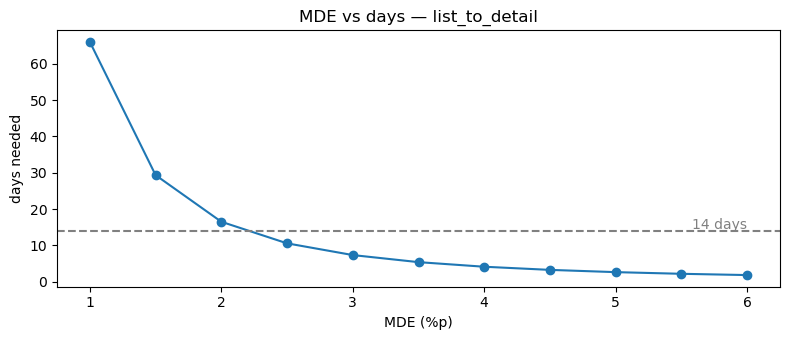

In [10]:
# [1.5-C] 필요한 기간
# 실험 전 데이터에서 대상 사용자의 하루 평균 '분모 세션 수'를 구하고, 그룹당으로 환산하세요.

num_col, den_col = METRICS[PRIMARY]
daily_denominator = target_pre.groupby("day")[den_col].sum().mean()
TRAFFIC_SHARE = 1.0
daily_per_group = daily_denominator * TRAFFIC_SHARE / 2

n_per_group = n_per_group_naive * design_effect
days_needed = n_per_group / daily_per_group
print(f"그룹당 필요한 분모 세션(디자인 효과 반영): {n_per_group:,.0f}")
print(f"그룹당 하루 분모 세션: {daily_per_group:,.0f} → 계산상 {days_needed:.1f}일")

# MDE를 바꾸면 기간이 어떻게 달라지는지
mdes = np.arange(0.01, 0.061, 0.005)
days = [NormalIndPower().solve_power(proportion_effectsize(p0 + m, p0), alpha=ALPHA, power=POWER) * design_effect / daily_per_group for m in mdes]
plt.figure(figsize=(8, 3.5))
plt.plot(mdes * 100, days, marker="o")
plt.axhline(14, ls="--", c="gray"); plt.text(mdes[-1] * 100, 14.5, "14 days", ha="right", color="gray")
plt.xlabel("MDE (%p)"); plt.ylabel("days needed"); plt.title(f"MDE vs days — {PRIMARY}")
plt.tight_layout(); plt.show()

### Q1.5 표본과 기간

1. A/A 테스트 결과 두 그룹의 차이는 유의했나요? 유의하지 않아야 정상인 이유는?
2. 사용자 단위 표준오차가 세션 독립 가정 표준오차보다 큰 이유를 "같은 사람의 세션"이라는 말을 써서 설명하세요.
3. 계산상 필요한 일수와 **최종으로 정한 실험 기간**은 각각 며칠인가요? 계산값보다 길게 잡았다면 그 이유는?
4. MDE를 어떤 근거로 정했나요? (통계가 아닌 **비즈니스 관점**의 근거를 포함)
5. (선택) `PRIMARY`를 `search_to_complete`로 바꿔 다시 계산해보세요. 기간이 어떻게 달라지나요? 이것이 1.3의 지표 역할 선택에 어떤 의미가 있나요?

**답변:**
1. A/A 차이는 +0.070%p, 95% CI [−1.449, +1.589]%p이고 사용자 단위 p=0.9281로 유의하지 않다. 두 그룹에 같은 경험을 제공하므로 실제 처치효과는 0이며 이번 결과는 그 기대와 양립한다. 물론 올바른 A/A라도 유의수준 5%에서는 우연히 유의할 수 있으므로, 한 번 유의하지 않았다는 사실만으로 배정·로깅의 완전성이 증명되지는 않는다.
2. 같은 사람의 세션은 구매 성향이나 탐색 습관을 공유한다. 세션을 모두 독립 표본으로 세면 반복 방문을 새로운 독립 정보처럼 취급해 불확실성을 작게 잡는다. 실제 A/A의 SE_delta=0.007752, SE_naive=0.006145이고, 디자인 효과는 약 1.591배다.
3. 독립 가정에서 그룹당 약 4,359개, 디자인 효과 반영 후 약 6936개의 목록 진입 세션이 필요하다(계산값 6,935.09를 올림). 그룹당 하루 평균은 944.75개여서 계산상 7.34일, 날짜 단위 최소값은 8일이다. 최종 기간은 14일(2026-03-02~03-15)로 정한다. 두 번의 주중·주말을 포함하는 실제 운영 관행, 효과의 시간 추이, 8일차 캠페인 전후 각 7일을 관찰할 여유를 고려할 수 있다.
4. MDE는 절대 3%p, 기준선 대비 약 6.25%로 정했다. 이는 목록 진입 1,000회당 상세 진입 30회를 더 만드는 수준으로, 기존 할인 표시를 개선하는 비교적 작은 개발·운영 변경의 우선순위를 검토할 만한 목표라고 가정했다. 기준선의 상세→결제완료 비율 약 29.63%가 유지된다면 목록 1,000회당 예약 약 8.9건 증가에 해당하지만, 이는 메커니즘이 유지된다는 가정에 따른 계획용 환산이며 실제 예약 증가를 보장하지 않는다. 개발비·기여이익 자료가 없으므로 손익분기점이 입증된 수치라고 주장하지 않고, 실제 의사결정에서는 그 자료로 목표를 재검토해야 한다. MDE는 검정력 설계의 목표 효과이며, 배포 시 신뢰구간 하한이 반드시 3%p를 넘어야 한다는 규칙은 두지 않았다.
5. 선택 문항도 별도 변수로 계산했다. 검색→결제완료의 기준선은 13.17%, 디자인 효과는 1.266배다. 같은 절대 MDE 3%p라면 계산상 2.70일로 짧아지지만, 이는 기준선 대비 22.78%라는 훨씬 큰 상대 개선을 요구하는 비교다. 같은 상대 개선 약 6.25%로 맞추면 MDE는 0.823%p, 필요한 기간은 33.75일(날짜 단위 34일)로 늘어난다. 따라서 '하위 퍼널이면 무조건 더 오래 걸린다'고 단정하기보다 동일한 사업적 개선 수준을 기준으로 비교해야 한다. 이번에는 변경 구간에 직접적인 목록→상세를 Primary로 두고 최종 예약은 가드레일로 감시하되, 14일 만에 작은 예약·매출 악화까지 배제할 수 있다고 주장하지 않는다.

## 1.6 실험 기간 중간에 외부 변화가 생긴다면?

마케팅팀에서 연락이 왔습니다. **실험 8일차부터 promotion 채널 대규모 광고 캠페인이 시작**되어 promotion 유입이 크게 늘어납니다.

1. 이 캠페인은 A그룹과 B그룹에 **똑같이** 영향을 줍니다. 그래도 실험 결과 해석에 문제가 생길까요? 무작위 배정의 성질로 설명하세요.
2. 캠페인으로 새로 들어오는 사용자는 평소 promotion 사용자와 어떻게 다를까요? 어떤 지표의 수준이 8일차 전후로 달라질까요?
3. 이 상황에서 설계를 바꾸거나 분석 계획에 추가할 것이 있다면? (캠페인을 피해 실험을 미루거나 줄이는 선택지도 검토)

**답변:**
1. 두 그룹을 **동시에 무작위 배정**하면 캠페인 영향도 기대상 균형 있게 분산되므로, 캠페인이 있다는 사실만으로 A/B 비교의 내적 타당성이 사라지지는 않는다. 다만 유한 표본에서 완벽한 균형을 보장하지는 않으며, 캠페인과 처치의 상호작용이 있으면 전체 효과는 이 기간의 평시·캠페인 트래픽이 섞인 평균이다. 따라서 다른 시기까지 같은 효과가 난다는 외적 타당성까지는 조금 애매하다.
2. 실제 대규모 광고 유입은 기존 고객보다 서비스 친숙도나 구매 의도가 낮고 기기·혜택 선호 구성도 다를 수 있다. 이 과제의 시뮬레이터에서는 별도의 신규 사용자 생성 대신 기존 promotion 사용자 세션 빈도 증가와 세션의 구매 성향 감소로 이를 표현한다. 따라서 유입량은 늘어도 목록→상세, 상세→객실, 검색→결제완료, 검색당 순매출의 수준은 낮아질 수 있다. 
3. 캠페인을 피하려고 7일로 줄이면 계산상 7.34일에도 못 미치고 캠페인 상황에 일반화할 정보도 사라진다. 따라서 실험은 14일 고정으로 유지하고, **1~7일 / 8~14일의 그룹별 수준과 효과**를 사전에 정한 보조 분석으로 본다. 사용자 배정을 계속 유지하며 일자별 노출·로그·기기 구성도 점검한다. 부분기간이나 기기별 p값 중 좋은 것만 골라 성공을 선언하지 않으며, 최종 판정은 전체 14일의 Primary로 한다. 신규성 여부도 일별 효과로 탐색하되, 이 그래프만으로 효과가 영구적이라고 단정하지 않는다. 

## 1.7 사전 판정 규칙

결과를 보기 **전에** 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

| 상황 | 판정 |
|---|---|
| 데이터 품질(SRM) 검정 p < 0.001 | 지표 해석과 배포 판정을 보류한다. 배정·노출·기기별 로깅 누락을 조사하고 수정 후 재실험한다. |
| Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음 | promotion 대상에 단계적으로 배포한다. 사용자 단위 Delta 양측 p<0.05이면서 B−A>0이어야 한다. 배포 중에도 취소·순매출·가격 오류를 감시한다. |
| Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화 | 배포 보류. 부작용 원인을 수정한 새 안으로 재실험하며, 클릭 증가만으로 배포하지 않는다. |
| Primary 유의하지 않음 | 이번 안은 배포 보류한다. 신뢰구간과 사업적 가치를 검토해 별도 재실험 또는 종료를 결정하며, 같은 실험을 결과에 맞춰 연장하지 않는다. |
| (선택) 그 밖에 미리 정해두고 싶은 규칙 | stopping="fixed", 14일 후 최종 검정 1회. 중간 p값으로 조기 성공 종료하지 않는다. 가격 오류·심각한 장애는 별도 운영 기준으로 즉시 대응한다. |

1. 가드레일의 악화는 사용자 단위 Delta 양측 **p<0.05**이면서 검색→결제완료·검색당 순매출은 B−A<0, 취소율은 B−A>0인 경우로 정의한다.
2. 가드레일 3개를 각각 명목 5%로 감시하며 다중검정 보정은 하지 않는다. 이 방식은 우연한 악화 신호로 배포를 보류할 가능성이 커지는 보수적인 안전 점검이며, 모든 가드레일의 무해성이 입증된다는 뜻은 아니다.
3. Secondary와 기간별·채널별 분석은 탐색용으로만 사용한다. 비열등성 마진을 정하지 않았으므로 '유의한 악화 없음'을 '허용 손실 이하임이 증명됨'으로 해석하지 않는다.


In [11]:
# [1.8] 최종 설계서 — 위에서 정한 값을 그대로 옮기세요. 이 셀이 Part 2의 실험을 결정합니다.

my_design = {
    "idea":           "A",      # "A" | "B" | "C"
    "target":         "promotion",      # "promotion" | "all"
    "unit":           "user",      # "user" | "session"
    "primary_metric": PRIMARY,
    "guardrails":     ["search_to_complete", "revenue_per_search", "cancel_rate"],      # 예: ["search_to_complete", "detail_to_room"]
    "secondary":      ["detail_to_room", "checkout_to_complete"],
    "alpha":          ALPHA,
    "power":          POWER,
    "mde_abs":        MDE,
    "traffic_share":  TRAFFIC_SHARE,
    "duration_days":  14,        # 1.5에서 정한 최종 기간 (3~42)
    "stopping":       "fixed",      # "fixed": 정한 기간까지 / "peek": 매일 확인하다 유의하면 중단
}
my_design

{'idea': 'A',
 'target': 'promotion',
 'unit': 'user',
 'primary_metric': 'list_to_detail',
 'guardrails': ['search_to_complete', 'revenue_per_search', 'cancel_rate'],
 'secondary': ['detail_to_room', 'checkout_to_complete'],
 'alpha': 0.05,
 'power': 0.8,
 'mde_abs': 0.03,
 'traffic_share': 1.0,
 'duration_days': 14,
 'stopping': 'fixed'}

---
# Part 2. 실행과 판정

여기서부터는 Part 1을 수정하지 마세요. 아래 셀을 실행하면 **여러분의 설계대로** 실험이 진행됩니다.

In [12]:
exp = run_experiment(my_design, SEED)
display(exp.head())

실험 기간: 2026-03-02 ~ 2026-03-15 (14일)
실험에 노출된 사용자: 11,743명 / 세션: 34,374개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


,session_id,user_id,channel,device,user_type,day,session_start,group,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,E00000000,200039,promotion,android,leisure,1,2026-03-02 10:18:41,A,1,1,0,0,0,0,None,0.0000,0,0.0000
1,E00000001,200070,promotion,android,leisure,1,2026-03-02 08:12:20,B,1,1,1,1,1,1,card,"204,400.0000",0,"204,400.0000"
2,E00000002,200072,promotion,android,business,1,2026-03-02 21:39:19,A,1,0,0,0,0,0,None,0.0000,0,0.0000
3,E00000003,200148,promotion,web,leisure,1,2026-03-02 12:05:43,B,1,1,0,0,0,0,None,0.0000,0,0.0000
4,E00000004,200148,promotion,web,leisure,1,2026-03-02 18:50:30,B,1,1,1,1,1,0,card,0.0000,0,0.0000


## 2.1 데이터 품질 — SRM 확인

결과 지표를 보기 전에 **배정 비율이 설계(50:50)대로인지** 먼저 확인합니다.

In [13]:
from scipy.stats import chisquare

# 주석 빈칸: 배정 단위가 사용자이므로, 그룹별 고유 사용자 수를 세어야 한다.
counts = exp.groupby("group")["user_id"].nunique()
print(counts)

total = counts.sum()
srm_p = chisquare(counts.values, f_exp=[total * 0.5, total * 0.5]).pvalue
print(f"SRM 검정 p-value: {srm_p:.2e}  →  {'SRM 의심! 결과 해석을 멈추세요' if srm_p < 0.001 else '통과'}")

# 어디서 어긋났는지 보기: 기기별 그룹 사용자 수
display(exp.groupby(["device", "group"])["user_id"].nunique().unstack())

group
A    5874
B    5869
Name: user_id, dtype: int64
SRM 검정 p-value: 9.63e-01  →  통과


group,A,B
device,,
android,2413,2428
ios,2213,2238
web,1248,1203


### Q2.1
1. SRM 검정 결과는? 통과하지 못했다면, 기기별 표에서 어디가 어긋났나요?
2. SRM이 있을 때 결과를 그대로 믿으면 안 되는 이유는? "어떤 사용자가 빠졌는가"의 관점에서 설명하세요.

**답변:**

1. 관측 고유 사용자는 A **5,874명**, B **5,869명**, SRM p=**0.9632**로 기준 0.001보다 크므로 통과했다. 기기별 A/B 사용자 수는 android 2,413/2,428, iOS 2,213/2,238, web 1,248/1,203으로 특정 기기 한쪽이 대규모로 사라진 징후도 보이지 않는다. 다만 SRM 통과는 모든 로깅 오류가 없다는 증명은 아니며, 이 자료의 검정은 최초 배정 전체 명부가 아니라 관측 세션에 등장한 노출 사용자 기준이다.
2. 예를 들어 B의 구형 웹 브라우저 사용자가 로그에서 빠지면, 그 사용자의 구매 성향·기기 경험까지 함께 빠져 나머지 B가 원래보다 좋은 집단처럼 보일 수 있다. 이때는 같은 모집단의 무작위 두 그룹이라는 전제가 깨져, 관측된 차이가 화면 효과인지 빠진 사용자 구성의 효과인지 분리할 수 없다. 전체 인원만 맞추거나 p값만 보정해서 해결할 수 없고 배정 명부·노출·이벤트 로그를 대조해 누락 원인을 고쳐야 한다.

## 2.2 지표 분석

`ratio_test(df, metric)`은 두 가지 표준오차를 함께 보여줍니다.
- `se_naive`, `p_naive`: 세션을 서로 독립인 관측으로 본 계산
- `se_delta`, `p_value`, `ci_low ~ ci_high`: 같은 사용자의 세션끼리 묶어서 계산 (**판정에는 이쪽을 사용**)

In [14]:
# [2.2-A] Primary + Guardrail + Secondary 결과표
metrics_to_check = [my_design["primary_metric"]] + my_design["guardrails"] + my_design["secondary"]

results = pd.DataFrame([ratio_test(exp, m, alpha=my_design["alpha"]) for m in metrics_to_check])
display(results)

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,list_to_detail,0.4340,0.4677,0.0338,0.0778,0.0196,0.0479,0.0000,0.0072,0.0056,0.0000
1,search_to_complete,0.1139,0.1229,0.0090,0.0794,0.0011,0.0170,0.0252,0.0040,0.0035,0.0094
2,revenue_per_search,"20,042.9570","21,215.6534","1,172.6965",0.0585,-319.2108,"2,664.6038",0.1234,761.1912,669.1671,0.0797
3,cancel_rate,0.0702,0.0824,0.0122,0.1732,-0.0041,0.0284,0.1430,0.0083,0.0083,0.1436
4,detail_to_room,0.6808,0.6911,0.0103,0.0152,-0.0057,0.0264,0.2079,0.0082,0.0078,0.1842
5,checkout_to_complete,0.6998,0.6946,-0.0052,-0.0074,-0.0288,0.0184,0.6656,0.0121,0.0120,0.6652


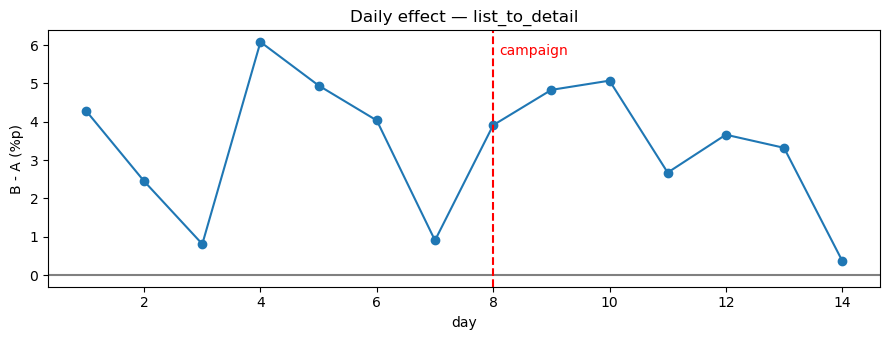

1~7일: diff=+0.0337, 95% CI [+0.0144, +0.0529]
8일~: diff=+0.0339, 95% CI [+0.0171, +0.0507]


In [15]:
# [2.2-B] 일별 Primary 효과 — 신규성 효과와 8일차(캠페인 시작) 전후 확인
num_col, den_col = METRICS[my_design["primary_metric"]]
daily = exp.groupby(["day", "group"]).agg(num=(num_col, "sum"), den=(den_col, "sum")).reset_index()
daily["rate"] = daily["num"] / daily["den"]

# 주석 빈칸: pivot 후 B - A를 계산하면 그날 하루의 ________ 를 볼 수 있다.
daily_diff = daily.pivot(index="day", columns="group", values="rate")
daily_diff["diff"] = daily_diff["B"] - daily_diff["A"]

plt.figure(figsize=(9, 3.5))
plt.plot(daily_diff.index, daily_diff["diff"] * 100, marker="o")
plt.axhline(0, c="gray"); plt.axvline(8, ls="--", c="red"); plt.text(8.1, plt.ylim()[1] * 0.9, "campaign", color="red")
plt.xlabel("day"); plt.ylabel("B - A (%p)"); plt.title(f"Daily effect — {my_design['primary_metric']}")
plt.tight_layout(); plt.show()

# 전반부(1~7일) vs 후반부(8일~) 효과
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, my_design["primary_metric"])
    print(f"{name}: diff={r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

### Q2.2
1. Primary의 효과를 **점추정이 아니라 신뢰구간으로** 한 문장으로 말하세요. (예: "목록 → 상세 전환율이 ○%p에서 ○%p 사이로 올랐다")
2. `se_naive`와 `se_delta` 중 어느 쪽이 더 큰가요? naive로 판정했다면 어떤 위험이 있나요?
3. 일별 그래프에서 효과가 기간 내내 비슷한가요, 아니면 초반에 몰려 있나요? 어떤 의미인가요?
4. Guardrail 지표는 어떻게 나왔나요? "유의한 악화 없음"과 "변화 없음이 증명됨"은 같은 말인가요?
5. A그룹과 B그룹의 Primary 지표 **수준**이 8일차 전후로 어떻게 달라졌나요? 그런데도 A/B 비교가 유효한 이유는?

**답변:**

1. promotion 사용자의 목록→상세 전환율 개선 효과에 대한 95% 신뢰구간은 +1.96~+4.79%p다. A=43.40%, B=46.77%, 차이 +3.38%p(상대 +7.78%), 사용자 단위 p=2.82×10⁻⁶이다. 그러나 신뢰구간은 0보다 위지만 MDE 3%p를 걸치므로, 실제 효과가 최소 3%p 이상이라고까지 입증한 것은 아니다.
2. Primary의 SE_delta=0.007211 > SE_naive=0.005585로, 사용자 단위 보정이 약 1.29배 크다. naive p=1.47×10⁻⁹, Delta p=2.82×10⁻⁶으로 이번에는 양쪽 모두 유의하지만, naive는 같은 사람의 반복 세션을 독립 정보로 세어 신뢰구간을 좁히고 유의성을 과장할 수 있다. 가드레일 중 취소율은 두 SE가 거의 같고 Delta가 오히려 조금 작으므로, 사용자 보정이 모든 지표에서 반드시 더 큰 SE를 준다고 일반화하지 않는다.
3. 일별 차이는 흔들리지만 초반에만 효과가 몰린 뚜렷한 모습은 없다. 1~7일 효과는 +3.37%p, 95% CI [+1.44,+5.29]%p, 8~14일은 +3.39%p, 95% CI [+1.71,+5.07]%p로 비슷하다. 이 14일 자료는 강한 초기 신규성만으로 설명되는 패턴을 지지하지 않지만, 장기 지속성이나 전후 효과의 완전한 동일성을 증명하지 않는다. 두 기간에 같은 사용자가 다시 등장하므로 기간별 추정치를 서로 독립인 실험처럼 취급해서도 안 된다.
4. 사전 가드레일 결과는 아래와 같다. 검색→결제완료는 좋은 방향으로 유의하게 움직였지만, 가드레일·보조 지표에 대한 다중검정 보정을 하지 않았으므로 이를 별도의 확증적 성공 주장으로 확대하지 않는다.

   | 가드레일 | A → B | B−A, 95% CI | Delta p값 | 해석 |
   |---|---|---|---|---|
   | 검색→결제완료 | 11.39% → 12.29% | +0.90%p [+0.11,+1.70]%p | 0.0252 | 유의한 악화 없음, 명목상 개선 |
   | 검색당 순매출 | 20,042.96원 → 21,215.65원 | +1,172.70원 [−319.21,+2,664.60]원 | 0.1234 | 악화가 유의하지 않지만 약 319원의 손실도 배제하지 못함 |
   | 취소율 | 7.02% → 8.24% | +1.22%p [−0.41,+2.84]%p | 0.1430 | 점추정은 나쁜 방향. 악화가 유의하지 않으나 최대 약 2.84%p 증가와도 양립 |

   여기서 '유의한 악화 없음'은 '변화 없음이 증명됨'과 다르다. 비열등성 마진과 검정력을 별도로 정하지 않았으므로 안전성 입증이라고 표현하지 않는다. Secondary는 상세→객실 +1.03%p(p=0.2079), checkout→완료 −0.52%p(p=0.6656)로 뚜렷한 차이를 확인하지 못했다. 
5. A는 **48.04% → 40.12%(−7.92%p)**, B는 **51.41% → 43.51%(−7.90%p)**로 캠페인 후 양쪽 수준이 모두 하락했다. B의 캠페인 이후 수치만 이전 기준선과 비교하면 실패로 오해할 수 있지만, 같은 기간의 무작위 A와 비교하면 차이는 약 +3.4%p로 유지된다. 캠페인은 세션 수 증가와 낮은 구매 의도를 함께 반영하므로 이 수준 하락과 방향이 맞는다. 다만 전후 비교만으로 캠페인의 인과효과 크기를 식별한 것은 아니며, 외부 변화가 기대상 두 그룹에 균형 있게 작용하고 배정·로깅·간섭 가정이 유지된다는 조건에서 A/B 비교가 어느 정도 유효하다.

## 2.3 판정

1.7의 사전 판정 규칙을 그대로 적용하세요.

- **해당하는 규칙 행:** SRM 통과 후, “Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음”.
- **판정:** **배포 — promotion 대상에 단계적으로 적용**.
- **결정 메모 (3~5문장):** 할인 적용가를 목록에 표시하자 상세 진입 개선 효과의 95% 신뢰구간이 +1.96~+4.79%p로 나타나, 같은 기간 기존 화면보다 더 많은 탐색을 만들었다. 검색→예약완료도 좋은 방향으로 움직였고 사전에 정한 가드레일에서 유의한 악화가 관측되지 않아, 정해 둔 규칙에 따라 promotion 사용자에게 단계적으로 배포한다. 기존 할인 정보를 보여 주는 변경이어서 추가 할인 예산을 전제하지 않지만, 실제 개발·운영비와 이익 자료가 없으므로 수익성이 확정됐다고 말하지는 않는다. 특히 취소율은 7.02%에서 8.24%로 높아졌고 신뢰구간도 넓어, 출시 확대 중 취소·순매출·가격 오류를 계속 감시하고 부작용 신호가 확인되면 노출을 되돌린다. 캠페인과 함께 측정한 14일 결과라는 점을 명시하고 평시와 장기 사용에서도 효과가 이어지는지 추가 확인한다.
- **다음 실험 아이디어 (1개):** 할인 적용가 옆에 “적용 조건과 취소·환불 조건”을 짧게 보여 주면 상세 진입 증가를 유지하면서 조건 오해로 인한 취소를 줄일 수 있다는 가설을 검증한다. 취소 증가가 이번에 확정된 것은 아니므로 이를 확인할 수 있도록 충분한 예약 수·취소 관찰 기간과 비열등성 마진을 새 실험 전에 정한다.

---
# Part 3. 심화 과제 — 아래 중 1개 선택

같은 사용자 데이터로 **설계 한 가지만 바꿔** 다시 실험하고, 결과가 왜 달라졌는지 분석하세요.

| 선택 | 바꿀 것 | 생각해볼 질문 |
|---|---|---|
| **A. 기간과 중단 규칙** | `duration_days`를 7로, 또는 `stopping`을 `"peek"`으로 | 언제 멈췄나? 효과 크기가 어떻게 달라졌나? 왜? |
| **B. 대상 범위** | `target`을 반대로 | 효과 크기와 표준오차가 어떻게 달라졌나? 어느 쪽이 의사결정에 유리한가? |
| **C. 배정 단위** | `unit`을 반대로 | 효과 크기가 왜 달라졌나? 사용자 경험 측면의 문제는? |

### 심화 과제 작성
- 선택한 항목: **B. 대상 범위**
- 바꾼 설계 값: `target="promotion"` → `target="all"` 한 가지. 아이디어 A, 사용자 배정, 트래픽 비율, MDE 3%p, 14일, fixed 및 나머지 설정은 유지한다.
- 원래 결과 vs 바뀐 결과 (핵심 숫자 2~3개): 아래 표 참고.
- 왜 달라졌는가: 모든 채널을 합치면 promotion의 문제를 크게 겪지 않는 사용자까지 평균에 포함되어 전체 효과는 희석된다. 한편 노출 사용자는 11,743명에서 55,213명으로 늘어 사용자 단위 표준오차는 작아진다. 실제 전체 대상 효과는 +0.96%p [95% CI +0.28~+1.64]%p, p=0.0058로 유의하지만 원래 효과 +3.38%p보다 작다. 별도 실행의 promotion 부분집단에서는 +2.78%p가 관측되어 희석 설명과 방향이 맞지만, 표본·그룹 배정·난수 소비 경로도 달라지므로 원래 실험과의 숫자 차이를 모두 대상 범위의 효과로 볼 수는 없다. 같은 SEED는 모집단 생성의 재현성을 주며, 두 실행이 모든 사용자에 대해 동일한 배정과 행동 난수를 공유한다는 뜻은 아니다.
- 실무에서 이 교훈을 적용한다면: 유의성만 비교하지 않고 어떤 모집단의 평균 효과가 배포 결정에 필요한지 먼저 정한다. 이번 promotion 한정 배포 결정에는 원래의 표적 실험이 더 직접적이며, 전체 적용을 결정하려면 비프로모션 사용자에 대한 가치와 비용을 따로 평가해야 한다. target="all" 실험도 SRM p=0.8215로 통과했지만, 모든 사용자에서 3%p가 개선된다는 근거는 없고 이 신뢰구간은 3%p보다 아래다. 사전 1.7 규칙에는 MDE 하한을 배포 조건으로 두지 않았으므로, 심화 실험을 본 뒤 그 규칙을 소급 변경하지 않는다.

| Primary 비교 | 원래: promotion | 변경: all |
|---|---:|---:|
| 효과 B−A | +3.3775%p | +0.9562%p |
| 사용자 단위 SE | 0.7211%p | 0.3467%p |
| 95% CI | [+1.9642,+4.7908]%p | [+0.2766,+1.6358]%p |
| Delta p값 | 0.00000282 | 0.005820 |


In [16]:
# [심화 과제 Skeleton]
alt_design = dict(my_design)
alt_design["target"] = "all"       # 바꿀 설계 하나

alt = run_experiment(alt_design, SEED)
alt_results = pd.DataFrame([ratio_test(alt, m) for m in metrics_to_check])
display(pd.concat({"원래 설계": results.set_index("metric"), "바꾼 설계": alt_results.set_index("metric")}, axis=1))

실험 기간: 2026-03-02 ~ 2026-03-15 (14일)
실험에 노출된 사용자: 55,213명 / 세션: 145,507개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


원래 설계                                            \
                               A           B       diff rel_diff    ci_low   
metric                                                                       
list_to_detail            0.4340      0.4677     0.0338   0.0778    0.0196   
search_to_complete        0.1139      0.1229     0.0090   0.0794    0.0011   
revenue_per_search   20,042.9570 21,215.6534 1,172.6965   0.0585 -319.2108   
cancel_rate               0.0702      0.0824     0.0122   0.1732   -0.0041   
detail_to_room            0.6808      0.6911     0.0103   0.0152   -0.0057   
checkout_to_complete      0.6998      0.6946    -0.0052  -0.0074   -0.0288   

                                                                        바꾼 설계  \
                        ci_high p_value se_delta se_naive p_naive           A   
metric                                                                          
list_to_detail           0.0479  0.0000   0.0072   0.0056  0.0000      0.5526   
search_to_complete       0.0170  0.0252   0.0040   0.0035  0.0094      0.1461   
revenue_per_search   2,664.6038  0.1234 761.1912 669.1671  0.0797 25,785.3376   
cancel_rate              0.0284  0.1430   0.0083   0.0083  0.1436      0.0771   
detail_to_room           0.0264  0.2079   0.0082   0.0078  0.1842      0.6822   
checkout_to_complete     0.0184  0.6656   0.0121   0.0120  0.6652      0.6933   

                                                                        \
                               B     diff rel_diff   ci_low    ci_high   
metric                                                                   
list_to_detail            0.5622   0.0096   0.0173   0.0028     0.0164   
search_to_complete        0.1501   0.0040   0.0274  -0.0001     0.0081   
revenue_per_search   26,473.1954 687.8578   0.0267 -99.4226 1,475.1382   
cancel_rate               0.0743  -0.0027  -0.0354  -0.0098     0.0044   
detail_to_room            0.6928   0.0106   0.0156   0.0036     0.0177   
checkout_to_complete      0.7003   0.0070   0.0102  -0.0033     0.0173   

                                                        
                     p_value se_delta se_naive p_naive  
metric                                                  
list_to_detail        0.0058   0.0035   0.0027  0.0004  
search_to_complete    0.0575   0.0021   0.0019  0.0316  
revenue_per_search    0.0868 401.6811 362.8973  0.0580  
cancel_rate           0.4526   0.0036   0.0036  0.4494  
detail_to_room        0.0029   0.0036   0.0034  0.0016  
checkout_to_complete  0.1803   0.0053   0.0052  0.1783

---
# Part 4. 회고

- 설계 단계에서 가장 고민했던 결정과 그 이유: **회고 초안 — 본인 검토 필요.** Primary를 목록→상세로 둘지 최종 예약으로 둘지의 선택이 핵심이다. 전자는 변경 구간에 직접적이고 민감하지만 클릭만 늘어도 성공처럼 보일 수 있어, 예약·순매출·취소를 함께 감시하는 설계가 필요하다.
- 결과를 보고 "설계를 바꾸고 싶다"고 느낀 순간이 있었나요? 있었다면 무엇이었나요?: AI가 사용자의 감정을 대신 확인할 수는 없다. 결과에서 재설계를 검토할 만한 부분은 취소율 +1.22%p의 불확실성이다. 다만 이를 본 뒤 이번 실험의 기준을 고치거나 기간을 늘리지 않고, 다음 실험에 취소의 비열등성 마진과 충분한 후속 관찰 기간을 반영하는 것이 맞다.
- 진단 결과를 실험으로 검증해보며 새로 알게 된 점 (다음 그로스 세션에서는 이런 진단을 직접 하는 법을 배웁니다): 채널 간 낮은 전환율은 개선할 위치를 알려 주지만 그 원인이 가격 표시인지까지 증명하지 않는다. 캠페인 이후 두 그룹의 전환 수준이 모두 떨어져도 같은 시점의 무작위 비교에서는 개선 효과가 남을 수 있다. 또한 세션 비율 지표와 사용자 배정을 동시에 사용할 수 있지만 같은 사용자의 반복 방문을 반영한 분산 추정이 필요하다.
- 가장 어려웠던 부분: 이 답안에서 통계적으로 주의가 필요했던 부분은 MDE의 절대·상대 기준을 구분하는 일과, 가드레일의 비유의를 안전성 입증으로 오해하지 않아야 하는 점이 다소 어려웠다. 

---
# Part 5. 제출 전 체크리스트

- [ ] Q0에서 실험이 필요한 처방과 바로 고쳐야 하는 처방을 구분했는가?
- [ ] 가설에 바꾸는 것, 행동 메커니즘, 지표와 방향이 모두 있는가?
- [ ] 모든 지표의 분자 / 분모 / Grain / Window를 명시했는가?
- [ ] 배정 단위와 분석 단위의 차이를 고려했는가? (A/A 테스트, 디자인 효과)
- [ ] MDE를 비즈니스 근거로 정했고, 기간을 계산값보다 짧지 않게 정했는가?
- [ ] 판정 규칙을 결과를 보기 전에 정했고, 결과를 본 뒤 Part 1을 수정하지 않았는가?
- [ ] SRM을 가장 먼저 확인했는가?
- [ ] 효과를 신뢰구간으로 말했는가?
- [ ] 기술블로그에 옮길 설계서, 그래프, 결정 메모를 정리했는가?
- [ ] 마지막 셀에 AI 활용 방법과 대화 내역을 붙였는가

---
# Part 6. 생성형 AI 활용 방법 + 대화 내역 (필수)

AI를 사용했다면 아래를 작성하고, **대화 내역을 붙여넣으세요.** 사용하지 않았다면 "사용하지 않음"이라고 적어주세요.

1. 어느 문항에서, 어떤 목적으로 AI를 썼나요?
2. AI의 답 중 **본인 데이터로 확인해보니 틀렸거나 맞지 않았던 것**이 있었나요?
3. 이번 과제에서 AI에게 맡길 수 없었던, **사람이 직접 판단해야 했던 결정**은 무엇이었나요?

### 대화 내역
(여기에 붙여넣기)